<a href="https://colab.research.google.com/github/saikatacharjee6417-a11y/AIML_PROBLEM/blob/main/Stroke_Prediction_SMOTE.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Stroke Prediction Using Machine Learning and SMOTE

**Subject:** Machine Learning Laboratory  |  **Program:** B.Tech CSE (AIML)

---

## 1. Title and Introduction

### Objective of the Experiment
1. Solve the **class imbalance** problem in the processed Stroke Dataset using **SMOTE** (Synthetic Minority Over-sampling Technique).
2. Train the same **six classifiers** (Logistic Regression, Decision Tree, Random Forest, SVM, KNN and ANN) on the **original imbalanced** training data and on the **SMOTE-balanced** training data.
3. Evaluate every model using **Accuracy, Precision, Recall, F1-Score and AUC-ROC** and display the **Confusion Matrix** of each model.
4. Compare the results of the original and SMOTE experiments and identify the **top three models** for stroke prediction on the balanced data.

### What is Class Imbalance?
A dataset is *imbalanced* when one class has far more samples than the other. In the stroke dataset, patients **without** stroke (class 0) are the large majority and patients **with** stroke (class 1) are the small minority.

### Why is it a problem in Stroke Prediction?
- A model can reach very high **accuracy** by predicting "No Stroke" for almost everybody, while missing the real stroke patients.
- Most algorithms try to minimise the overall error, so they get biased towards the **majority class**.
- In healthcare, a **False Negative** (a stroke patient predicted as healthy) is far more costly than a False Positive, so **Recall** of the stroke class matters a lot.

### Purpose of SMOTE
SMOTE creates **new synthetic minority samples** instead of simply duplicating existing ones. For a minority sample it finds its *k* nearest minority neighbours and generates a new point on the line joining the sample and one of those neighbours. This balances the training data so that the classifiers can learn the stroke class better.

> **Golden rule:** SMOTE is applied **only on the training data, after the train-test split**. The test data is never touched, so the evaluation stays fair and realistic.

## 2. Import Libraries

The cell below installs **imbalanced-learn** (only if it is missing) and imports all required libraries.
The ANN in the original laboratory notebook is built with Scikit-learn's `MLPClassifier`, so **TensorFlow/Keras is not required** here.

In [1]:
import sys, subprocess, warnings, os, glob
warnings.filterwarnings("ignore")

# Install imbalanced-learn (SMOTE) only if it is not already available (needed in Google Colab)
try:
    import imblearn
except ImportError:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "imbalanced-learn"])
    import imblearn

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, roc_curve, confusion_matrix)
from imblearn.over_sampling import SMOTE

sns.set_style("whitegrid")
plt.rcParams["figure.dpi"] = 100

RANDOM_STATE = 42
print("NumPy version          :", np.__version__)
print("Pandas version         :", pd.__version__)
print("imbalanced-learn version:", imblearn.__version__)

NumPy version          : 2.4.6
Pandas version         : 2.2.3
imbalanced-learn version: 0.14.2


## 3. Load Dataset

**How to upload the dataset (default - local upload):**
1. Run the next cell.
2. Click **Choose Files** and select `stroke_processed_5k new.csv` from your computer.
3. Wait until the upload finishes. The notebook continues automatically.

If the CSV is already present in the Colab session (for example, uploaded earlier), it is used directly. Google Drive can be used instead by un-commenting the optional lines in the cell.

In [2]:
# ---- Locate or upload the CSV file ----
def find_local_csv():
    # Look for the processed stroke CSV in the current Colab session
    patterns = ["stroke_processed_5k_new.csv", "stroke_processed_5k new.csv",
                "stroke_processed_5k*.csv", "/content/stroke_processed_5k*.csv"]
    for pattern in patterns:
        matches = glob.glob(pattern)
        if matches:
            return matches[0]
    return None

filename = find_local_csv()

if filename is None:
    # DEFAULT: local upload through the Colab file chooser
    from google.colab import files
    uploaded = files.upload()          # select 'stroke_processed_5k new.csv' when prompted
    filename = list(uploaded.keys())[0]

# --- OPTIONAL: load from Google Drive instead (remove the '#' to use) ---
# from google.colab import drive
# drive.mount('/content/drive')
# filename = "/content/drive/MyDrive/stroke_processed_5k new.csv"

print("Using file:", filename)

Saving stroke_processed_5k new.csv to stroke_processed_5k new.csv
Using file: stroke_processed_5k new.csv


In [3]:
df = pd.read_csv(filename)

# ---- Identify / verify the target column named 'stroke' ----
target_matches = [c for c in df.columns if c.strip().lower() == "stroke"]
if not target_matches:
    raise ValueError("Target column 'stroke' not found. Columns available: " + str(list(df.columns)))
target = target_matches[0]
print("Target column verified:", target)

print("\nFirst five rows:")
display(df.head())
print("Dataset shape (rows, columns):", df.shape)

Target column verified: stroke

First five rows:


,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,1,1.051434,0,1,1,2,1,2.706375,1.005086,1,1
1,0,0.786070,0,0,1,3,0,2.121559,-0.098981,2,1
2,1,1.626390,0,1,1,2,0,-0.005028,0.472536,2,1
3,0,0.255342,0,0,1,2,1,1.437358,0.719327,3,1
4,0,1.582163,1,0,1,3,0,1.501184,-0.631531,2,1


Dataset shape (rows, columns): (5110, 11)


In [4]:
# Dataset information (data types, non-null counts)
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5110 entries, 0 to 5109
Data columns (total 11 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   gender             5110 non-null   int64  
 1   age                5110 non-null   float64
 2   hypertension       5110 non-null   int64  
 3   heart_disease      5110 non-null   int64  
 4   ever_married       5110 non-null   int64  
 5   work_type          5110 non-null   int64  
 6   Residence_type     5110 non-null   int64  
 7   avg_glucose_level  5110 non-null   float64
 8   bmi                5110 non-null   float64
 9   smoking_status     5110 non-null   int64  
 10  stroke             5110 non-null   int64  
dtypes: float64(3), int64(8)
memory usage: 439.3 KB


In [5]:
# Descriptive statistics
display(df.describe().T)

,count,mean,std,min,25%,50%,75%,max
gender,5110.0,4.142857e-01,0.493044,0.000000,0.000000,0.000000,1.000000,2.000000
age,5110.0,4.449583e-17,1.000098,-1.908261,-0.806115,0.078432,0.786070,1.714845
hypertension,5110.0,9.745597e-02,0.296607,0.000000,0.000000,0.000000,0.000000,1.000000
heart_disease,5110.0,5.401174e-02,0.226063,0.000000,0.000000,0.000000,0.000000,1.000000
ever_married,5110.0,6.561644e-01,0.475034,0.000000,0.000000,1.000000,1.000000,1.000000
work_type,5110.0,2.167710e+00,1.090293,0.000000,2.000000,2.000000,3.000000,4.000000
Residence_type,5110.0,5.080235e-01,0.499985,0.000000,0.000000,1.000000,1.000000,1.000000
avg_glucose_level,5110.0,1.168015e-16,1.000098,-1.126958,-0.638322,-0.314995,0.175408,3.657145
bmi,5110.0,-3.893385e-17,1.000098,-2.411027,-0.657509,-0.098981,0.511503,8.928390
smoking_status,5110.0,1.376908e+00,1.071534,0.000000,0.000000,2.000000,2.000000,3.000000


## 4. Exploratory Data Analysis (EDA)

We now check the distribution of the target variable `stroke` (0 = No Stroke, 1 = Stroke).

Target class distribution:


,Class,Records,Percentage (%)
0,No Stroke,4861,95.13
1,Stroke,249,4.87


Class 0 (No Stroke) records: 4861
Class 1 (Stroke) records   : 249
Imbalance ratio (majority : minority) = 19.52 : 1


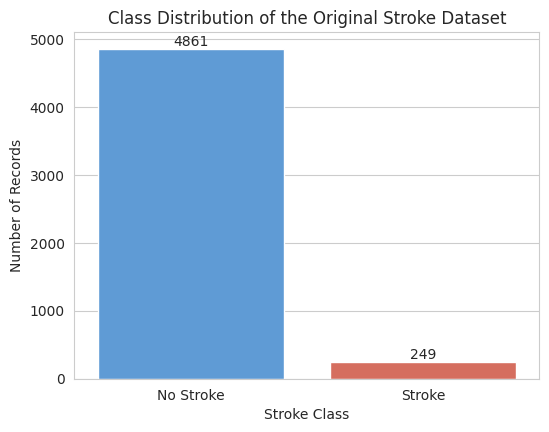

In [6]:
class_labels = ["No Stroke", "Stroke"]

class_counts = df[target].value_counts().sort_index()
class_percent = df[target].value_counts(normalize=True).sort_index() * 100

dist_df = pd.DataFrame({"Class": class_labels,
                        "Records": class_counts.values,
                        "Percentage (%)": class_percent.round(2).values},
                       index=[0, 1])
print("Target class distribution:")
display(dist_df)

print(f"Class 0 (No Stroke) records: {class_counts[0]}")
print(f"Class 1 (Stroke) records   : {class_counts[1]}")
print(f"Imbalance ratio (majority : minority) = {class_counts[0] / class_counts[1]:.2f} : 1")

# Count plot
plt.figure(figsize=(6, 4.5))
ax = sns.countplot(x=target, data=df, hue=target, palette=["#4c9be8", "#e8604c"], legend=False)
ax.set_xticks([0, 1])
ax.set_xticklabels(class_labels)
for container in ax.containers:
    ax.bar_label(container, fontsize=10)
plt.title("Class Distribution of the Original Stroke Dataset")
plt.xlabel("Stroke Class")
plt.ylabel("Number of Records")
plt.show()

### Why is the dataset imbalanced?
Stroke is a **rare medical event**: in a general population only a small fraction of people suffer a stroke, so the collected records naturally contain far more "No Stroke" patients than "Stroke" patients. The class counts and percentages above confirm this - the Stroke class is only about 5 out of every 100 records. A classifier trained directly on such data sees very few stroke examples and tends to ignore them.

## 5. Data Preprocessing

The uploaded file is the **processed** stroke dataset (as in the original laboratory notebook): categorical columns are already integer-encoded and numerical columns are already standardized. So the original preprocessing logic is preserved and **no extra preprocessing is repeated** unless the checks below show that it is needed.

Steps:
1. Separate `X` (independent variables) and `y` (target `stroke`).
2. Check missing values and duplicate records.
3. Encode categorical (text) columns only if any exist.
4. Split the data 80:20 with `random_state=42` and `stratify=y`.
5. Check whether scaling is already done. If not, the scaler is **fitted on the training data only** (no data leakage).

In [7]:
# ---- 1. Missing values and duplicates ----
print("Total missing values :", int(df.isnull().sum().sum()))
n_dup = int(df.duplicated().sum())
print("Duplicate records    :", n_dup)
if n_dup > 0:
    df = df.drop_duplicates().reset_index(drop=True)
    print("Duplicates removed. New shape:", df.shape)

# ---- 2. Separate X and y ----
X = df.drop(columns=[target])
y = df[target]

# ---- 3. Encode categorical columns only if any text columns exist ----
cat_cols = X.select_dtypes(exclude="number").columns.tolist()
print("Non-numeric (categorical) columns:", cat_cols if cat_cols else "None - already encoded")
if cat_cols:
    X = pd.get_dummies(X, columns=cat_cols, drop_first=True, dtype=int)

print("Feature columns used:", X.columns.tolist())

Total missing values : 0
Duplicate records    : 0
Non-numeric (categorical) columns: None - already encoded
Feature columns used: ['gender', 'age', 'hypertension', 'heart_disease', 'ever_married', 'work_type', 'Residence_type', 'avg_glucose_level', 'bmi', 'smoking_status']


In [8]:
# ---- 4. Train-test split (80:20, stratified, random_state=42) ----
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)

# ---- 5a. Impute missing values (only if any) - fitted on training data only ----
if X_train.isnull().sum().sum() > 0 or X_test.isnull().sum().sum() > 0:
    imputer = SimpleImputer(strategy="median")
    X_train = pd.DataFrame(imputer.fit_transform(X_train), columns=X.columns, index=X_train.index)
    X_test = pd.DataFrame(imputer.transform(X_test), columns=X.columns, index=X_test.index)
    print("Missing values were imputed using the training-set median.")

# ---- 5b. Scaling check: continuous columns should have mean ~ 0 and std ~ 1 ----
continuous_cols = [c for c in X.columns if X[c].nunique() > 10]
stats = X_train[continuous_cols].agg(["mean", "std"]).T
print("\nContinuous columns (training data statistics):")
display(stats.round(4))

already_scaled = bool(((stats["mean"].abs() < 0.1) & ((stats["std"] - 1).abs() < 0.1)).all())
if already_scaled:
    print("Numerical features are already standardized -> no extra scaling needed.")
else:
    # Fit the scaler on TRAINING data only, then apply it to the test data (no leakage)
    scaler = StandardScaler()
    X_train[continuous_cols] = scaler.fit_transform(X_train[continuous_cols])
    X_test[continuous_cols] = scaler.transform(X_test[continuous_cols])
    print("Features were not standardized -> StandardScaler fitted on the training set only.")

print("\nX_train shape:", X_train.shape, "| X_test shape:", X_test.shape)
print("\nTrain class distribution (%):")
print((y_train.value_counts(normalize=True).sort_index() * 100).round(2).to_string())
print("\nTest class distribution (%):")
print((y_test.value_counts(normalize=True).sort_index() * 100).round(2).to_string())


Continuous columns (training data statistics):


,mean,std
age,0.0056,0.9994
avg_glucose_level,0.0037,0.9996
bmi,0.0034,1.0084


Numerical features are already standardized -> no extra scaling needed.

X_train shape: (4088, 10) | X_test shape: (1022, 10)

Train class distribution (%):
stroke
0    95.13
1     4.87

Test class distribution (%):
stroke
0    95.11
1     4.89


> **No data leakage:** the split is done **before** SMOTE; the test set stays untouched. Scaling (if it were needed) is fitted on the training data only. Because the data is already standardized, SMOTE is applied directly on the training features, and SMOTE is the **last** step applied to the training data.

### Reusable functions for training and evaluation

To avoid repeating code, the helper functions below are used for **both** experiments (Original and SMOTE).

- `build_models()` returns the six classifiers with the **same configuration as the original laboratory notebook** (fresh, untrained objects each time).
- `get_scores()` returns the stroke probability using `predict_proba()` (or `decision_function()` if a model has no `predict_proba`).
- `train_and_evaluate()` trains all six models on the given training data and evaluates them on the **same untouched test set**.
- `plot_confusion_matrices()` and `plot_roc_curves()` draw the confusion matrices and ROC curves.

In [9]:
MODEL_ORDER = ["Logistic Regression", "Decision Tree", "Random Forest", "SVM", "KNN", "ANN"]
METRICS = ["Accuracy", "Precision", "Recall", "F1-Score", "AUC-ROC"]

def build_models():
    # Same six models and hyper-parameters as the original laboratory notebook
    return {
        "Logistic Regression": LogisticRegression(class_weight="balanced", max_iter=1000, random_state=RANDOM_STATE),
        "Decision Tree": DecisionTreeClassifier(max_depth=5, class_weight="balanced", random_state=RANDOM_STATE),
        "Random Forest": RandomForestClassifier(n_estimators=200, max_depth=8, min_samples_leaf=5,
                                                class_weight="balanced", random_state=RANDOM_STATE),
        "SVM": SVC(kernel="rbf", class_weight="balanced", probability=True, random_state=RANDOM_STATE),
        "KNN": KNeighborsClassifier(n_neighbors=5),
        "ANN": MLPClassifier(hidden_layer_sizes=(64, 32), activation="relu", solver="adam",
                             max_iter=1000, random_state=RANDOM_STATE),
    }

def get_scores(model, X_data):
    # Probability / score of the positive class (Stroke = 1) used for AUC-ROC and ROC curves
    if hasattr(model, "predict_proba"):
        return model.predict_proba(X_data)[:, 1]
    return model.decision_function(X_data)

def train_and_evaluate(X_tr, y_tr, X_te, y_te):
    # Train all six models on (X_tr, y_tr) and evaluate on the same test set (X_te, y_te)
    rows, store = [], {}
    for name, model in build_models().items():
        model.fit(X_tr, y_tr)
        y_pred = model.predict(X_te)
        y_score = get_scores(model, X_te)

        rows.append({"Model": name,
                     "Accuracy":  accuracy_score(y_te, y_pred),
                     "Precision": precision_score(y_te, y_pred, zero_division=0),
                     "Recall":    recall_score(y_te, y_pred, zero_division=0),
                     "F1-Score":  f1_score(y_te, y_pred, zero_division=0),
                     "AUC-ROC":   roc_auc_score(y_te, y_score)})

        fpr, tpr, _ = roc_curve(y_te, y_score)
        store[name] = {"model": model, "y_pred": y_pred, "y_score": y_score,
                       "cm": confusion_matrix(y_te, y_pred, labels=[0, 1]),
                       "fpr": fpr, "tpr": tpr}
        print(f"  trained and evaluated: {name}")
    results = pd.DataFrame(rows).set_index("Model").loc[MODEL_ORDER]
    return results, store

def plot_confusion_matrices(store, dataset_type, cmap):
    # One heatmap per model (2 rows x 3 columns); each cell shows TN / FP / FN / TP with its count
    fig, axes = plt.subplots(2, 3, figsize=(17, 10))
    for ax, name in zip(axes.ravel(), MODEL_ORDER):
        cm = store[name]["cm"]
        tn, fp, fn, tp = cm.ravel()
        annot = np.array([[f"TN\n{tn}", f"FP\n{fp}"],
                          [f"FN\n{fn}", f"TP\n{tp}"]])
        sns.heatmap(cm, annot=annot, fmt="", cmap=cmap, cbar=False, ax=ax,
                    annot_kws={"fontsize": 14, "fontweight": "bold"},
                    xticklabels=class_labels, yticklabels=class_labels,
                    linewidths=1, linecolor="white")
        ax.set_title(f"Confusion Matrix - {name} ({dataset_type})", fontsize=12)
        ax.set_xlabel("Predicted")
        ax.set_ylabel("Actual")
    plt.suptitle(f"Confusion Matrices of All Six Models - {dataset_type} Training Data", fontsize=15, y=1.01)
    plt.tight_layout()
    plt.show()

def plot_roc_curves(store, results, dataset_type, ax):
    for name in MODEL_ORDER:
        ax.plot(store[name]["fpr"], store[name]["tpr"], linewidth=2,
                label=f"{name} (AUC = {results.loc[name, 'AUC-ROC']:.4f})")
    ax.plot([0, 1], [0, 1], "k--", label="Random Classifier (AUC = 0.5000)")
    ax.set_xlabel("False Positive Rate")
    ax.set_ylabel("True Positive Rate")
    ax.set_title(f"ROC Curves - Six Models ({dataset_type} Training Data)")
    ax.legend(loc="lower right")
    ax.grid(True)

print("Helper functions defined.")

Helper functions defined.


## 6. Original Imbalanced Dataset - Six ML Models

All six models are trained on the **original imbalanced** training set (`X_train`, `y_train`) and evaluated on the untouched test set (`X_test`, `y_test`).

Precision, Recall and F1-Score are calculated for the **Stroke class (1)**. `zero_division=0` avoids errors when a model predicts no Stroke cases at all.

| Model | Configuration (same as original notebook) |
|---|---|
| Logistic Regression | `class_weight="balanced"`, `max_iter=1000` |
| Decision Tree | `max_depth=5`, `class_weight="balanced"` |
| Random Forest | `n_estimators=200`, `max_depth=8`, `min_samples_leaf=5`, `class_weight="balanced"` |
| SVM | RBF kernel, `class_weight="balanced"`, `probability=True` |
| KNN | `n_neighbors=5` |
| ANN | `MLPClassifier`, hidden layers (64, 32), ReLU, Adam, `max_iter=1000` |

In [10]:
print("Training six models on the ORIGINAL imbalanced training data...")
results_original, store_original = train_and_evaluate(X_train, y_train, X_test, y_test)

print("\nResults - Original Imbalanced Dataset (evaluated on the untouched test set):")
display(results_original.style.format("{:.4f}"))

Training six models on the ORIGINAL imbalanced training data...
  trained and evaluated: Logistic Regression
  trained and evaluated: Decision Tree
  trained and evaluated: Random Forest
  trained and evaluated: SVM
  trained and evaluated: KNN
  trained and evaluated: ANN

Results - Original Imbalanced Dataset (evaluated on the untouched test set):


,Accuracy,Precision,Recall,F1-Score,AUC-ROC
Model,,,,,
Logistic Regression,0.7515,0.1408,0.8000,0.2395,0.8389
Decision Tree,0.8258,0.1768,0.7000,0.2823,0.8093
Random Forest,0.8591,0.2062,0.6600,0.3143,0.8408
SVM,0.7123,0.1187,0.7600,0.2054,0.8156
KNN,0.9442,0.0000,0.0000,0.0000,0.6308
ANN,0.9295,0.1765,0.1200,0.1429,0.7514


## 7. Original Dataset Confusion Matrices

Rows show the **Actual** class and columns show the **Predicted** class.
**TN** = No Stroke correctly predicted, **FP** = false alarm, **FN** = missed stroke patient, **TP** = stroke correctly detected.

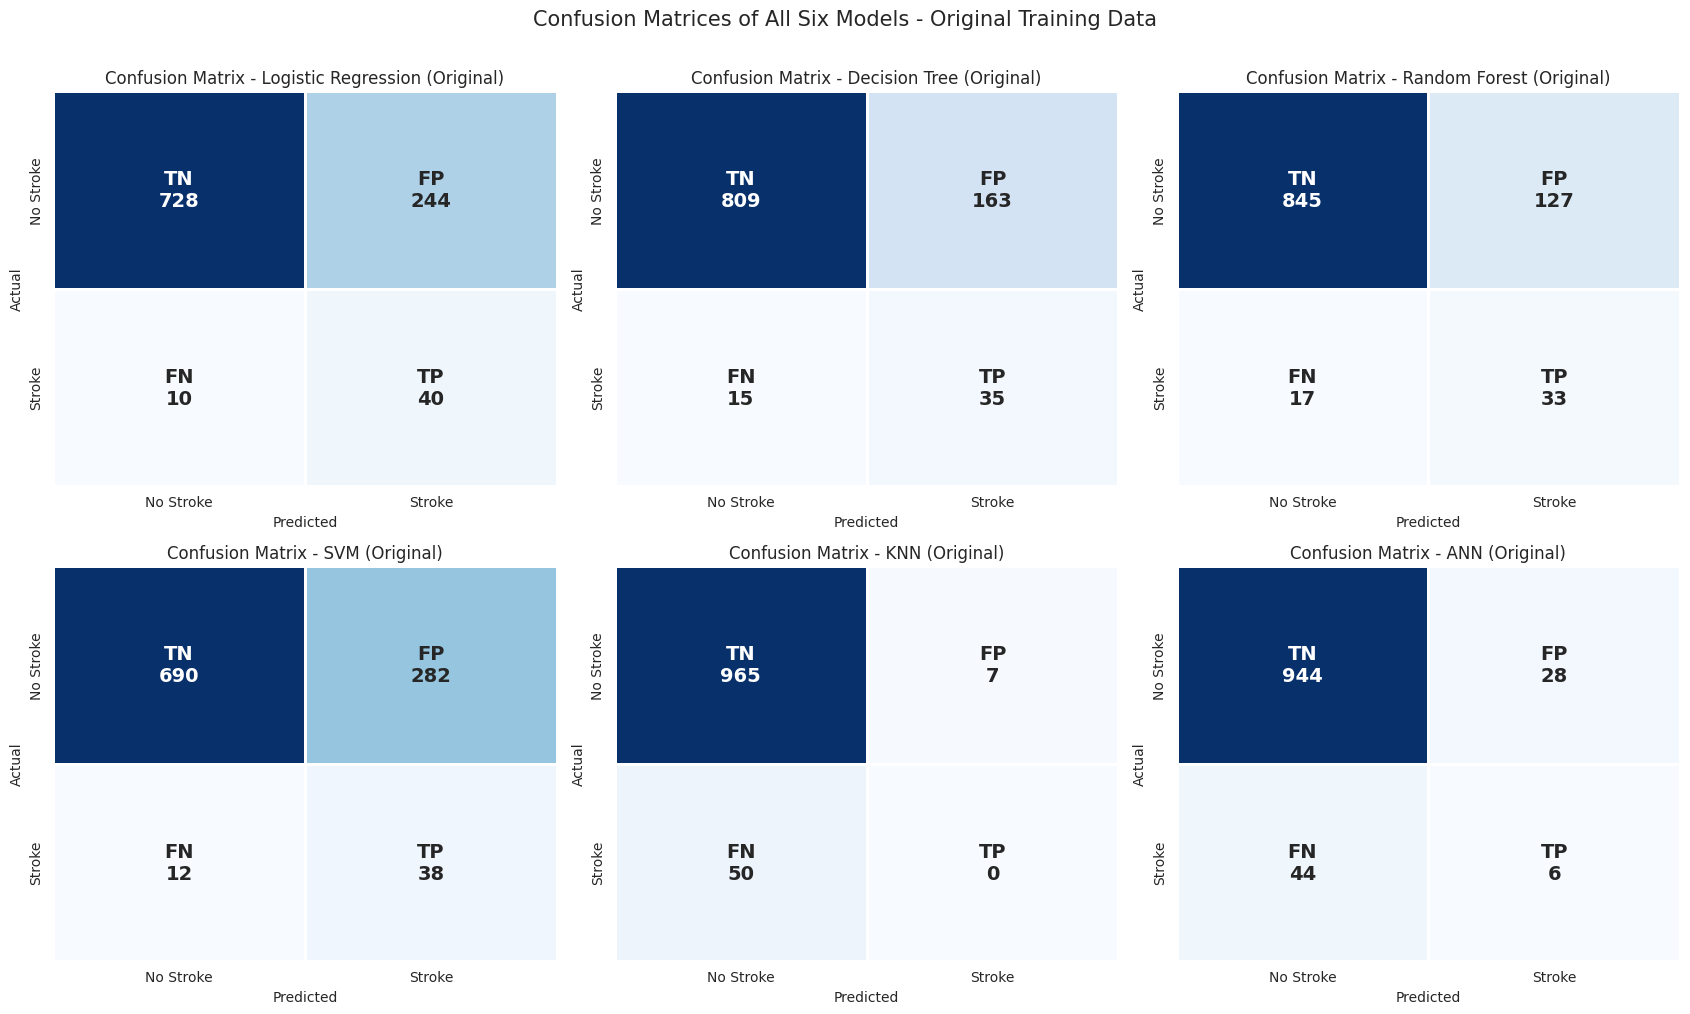

In [11]:
plot_confusion_matrices(store_original, "Original", cmap="Blues")

## 8. Apply SMOTE

SMOTE is applied **only to the training data** (`X_train`, `y_train`).
The test data is **not** balanced and is kept unchanged, so the comparison with the original experiment is fair.

Since the features are already standardized (checked in Section 5), no further scaling is required before SMOTE. The order of operations is: **split -> (scaling fitted on train, if needed) -> SMOTE on training data only**.

In [12]:
# Apply SMOTE ONLY on the training data
smote = SMOTE(random_state=RANDOM_STATE)
X_train_smote, y_train_smote = smote.fit_resample(X_train, y_train)

# ---- Class distribution before and after SMOTE ----
before = y_train.value_counts().sort_index()
after = y_train_smote.value_counts().sort_index()
smote_dist = pd.DataFrame({"Before SMOTE": before.values, "After SMOTE": after.values},
                          index=["Class 0 (No Stroke)", "Class 1 (Stroke)"])
smote_dist.loc["Total"] = smote_dist.sum()
print("Training-set class distribution:")
display(smote_dist)

# ---- Verify that both classes are equal after SMOTE ----
assert after[0] == after[1], "Classes are not balanced after SMOTE!"
print(f"Verified: both classes have {after[0]} samples after SMOTE.")
print(f"Synthetic Stroke samples created: {after[1] - before[1]}")
print(f"Test set unchanged: {X_test.shape[0]} samples "
      f"({int((y_test == 0).sum())} No Stroke, {int((y_test == 1).sum())} Stroke)")

Training-set class distribution:


,Before SMOTE,After SMOTE
Class 0 (No Stroke),3889,3889
Class 1 (Stroke),199,3889
Total,4088,7778


Verified: both classes have 3889 samples after SMOTE.
Synthetic Stroke samples created: 3690
Test set unchanged: 1022 samples (972 No Stroke, 50 Stroke)


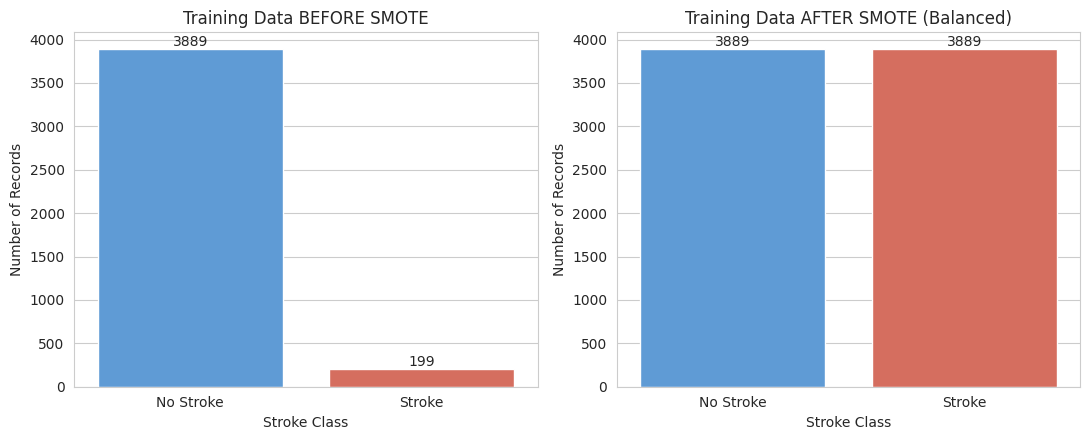

In [13]:
# ---- Count plots: before vs after SMOTE (training data) ----
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, data, title in zip(axes, [y_train, y_train_smote],
                           ["Training Data BEFORE SMOTE", "Training Data AFTER SMOTE (Balanced)"]):
    sns.countplot(x=np.asarray(data), hue=np.asarray(data), palette=["#4c9be8", "#e8604c"], legend=False, ax=ax)
    ax.set_xticks([0, 1])
    ax.set_xticklabels(class_labels)
    for container in ax.containers:
        ax.bar_label(container, fontsize=10)
    ax.set_title(title)
    ax.set_xlabel("Stroke Class")
    ax.set_ylabel("Number of Records")
plt.tight_layout()
plt.show()

In [14]:
# Informative check: the file has integer-coded categorical columns, but SMOTE interpolates between
# neighbours, so synthetic rows can contain non-integer values in such columns.
n_original = len(X_train)                       # imblearn appends the synthetic samples after the original rows
synthetic = X_train_smote.iloc[n_original:]
discrete_cols = [c for c in X.columns if X[c].nunique() <= 10]
frac_fractional = (~np.isclose(synthetic[discrete_cols] % 1, 0)
                   & ~np.isclose(synthetic[discrete_cols] % 1, 1)).any(axis=1).mean()
print(f"Synthetic samples with a fractional value in at least one encoded categorical column: {frac_fractional * 100:.1f}%")
print("(A known limitation of plain SMOTE on label-encoded features; see Limitations in the Conclusion.)")

Synthetic samples with a fractional value in at least one encoded categorical column: 0.0%
(A known limitation of plain SMOTE on label-encoded features; see Limitations in the Conclusion.)


## 9. SMOTE-Balanced Dataset - Six ML Models

The **same six classifiers with exactly the same configurations** are trained again, now on `X_train_smote` and `y_train_smote`, and evaluated on the **same untouched original test set**.

In [15]:
print("Training six models on the SMOTE-balanced training data...")
results_smote, store_smote = train_and_evaluate(X_train_smote, y_train_smote, X_test, y_test)

print("\nResults - SMOTE-Balanced Dataset (evaluated on the same untouched test set):")
display(results_smote.style.format("{:.4f}"))

Training six models on the SMOTE-balanced training data...
  trained and evaluated: Logistic Regression
  trained and evaluated: Decision Tree
  trained and evaluated: Random Forest
  trained and evaluated: SVM
  trained and evaluated: KNN
  trained and evaluated: ANN

Results - SMOTE-Balanced Dataset (evaluated on the same untouched test set):


,Accuracy,Precision,Recall,F1-Score,AUC-ROC
Model,,,,,
Logistic Regression,0.7593,0.1423,0.7800,0.2407,0.8221
Decision Tree,0.7593,0.1343,0.7200,0.2264,0.8056
Random Forest,0.7534,0.1314,0.7200,0.2222,0.8213
SVM,0.7534,0.1259,0.6800,0.2125,0.7837
KNN,0.7847,0.0913,0.3800,0.1473,0.6779
ANN,0.8483,0.1053,0.2800,0.1530,0.7351


## 10. SMOTE Confusion Matrices

Six confusion matrices for the models trained on the SMOTE-balanced data (together with the six in Section 7, there are **12 confusion matrices** in total).

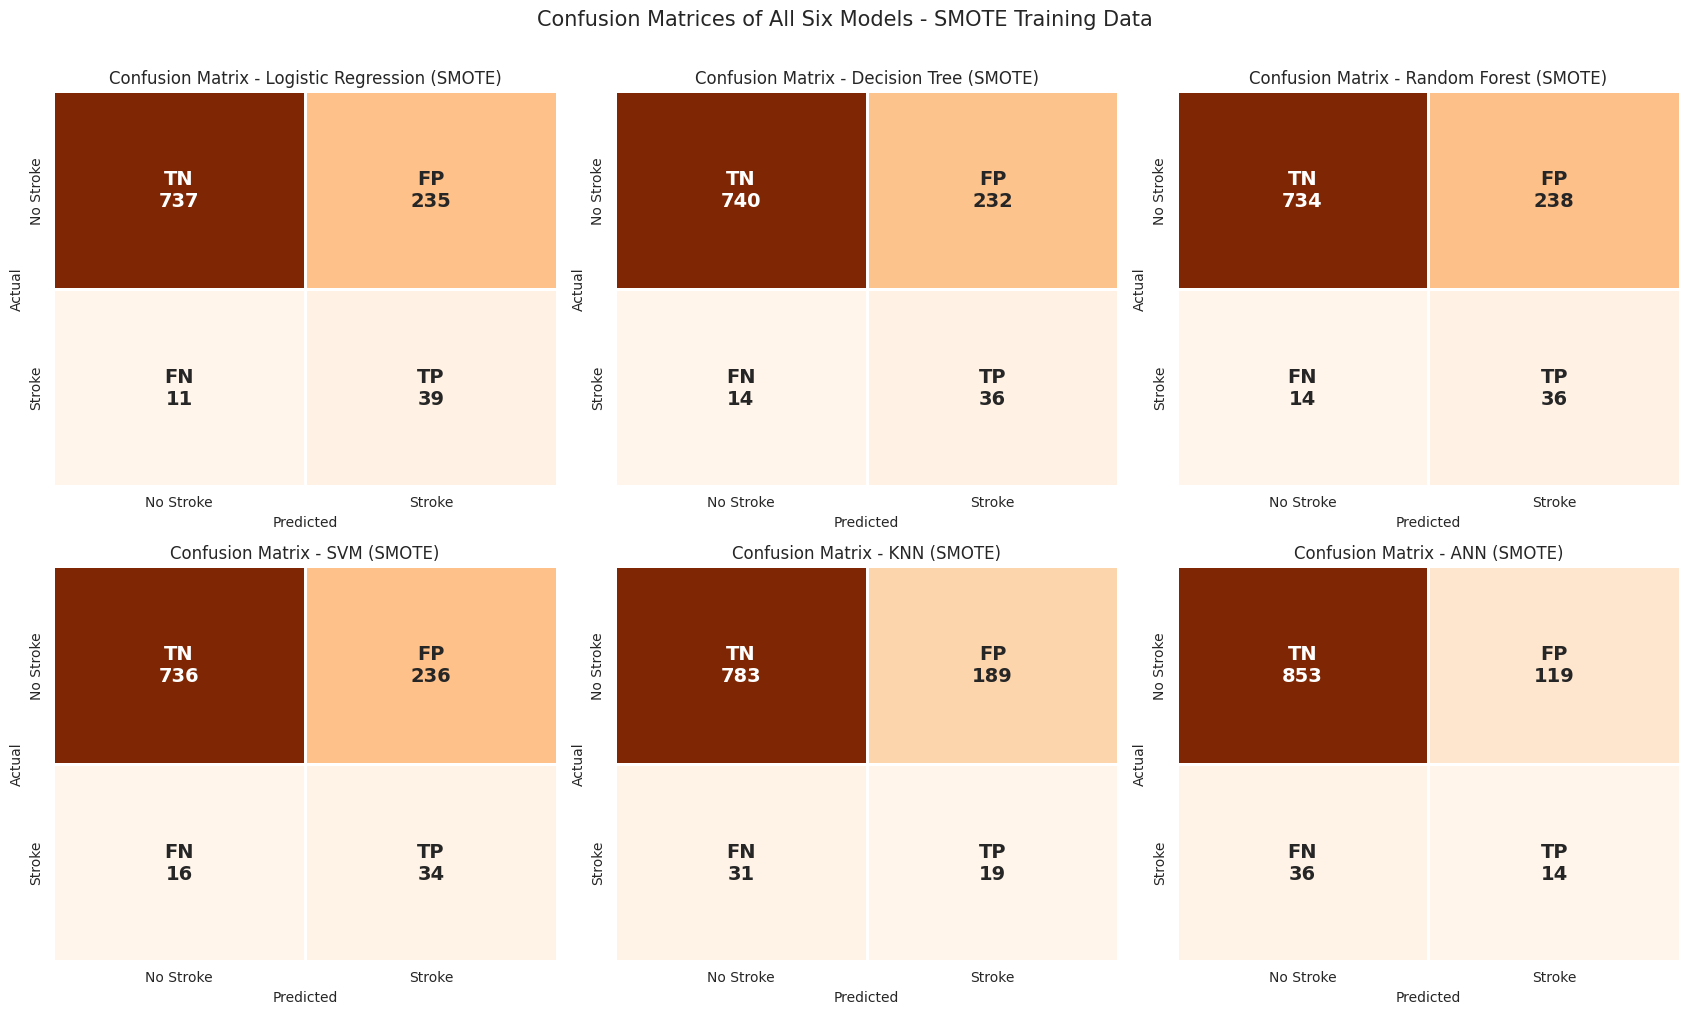

In [16]:
plot_confusion_matrices(store_smote, "SMOTE", cmap="Oranges")

## 11. ROC Curves

ROC curves are drawn from the stroke probability scores (`predict_proba()`; `decision_function()` is used only if a model has no `predict_proba`). The AUC value of every model is shown in the legend and the dashed diagonal is a random classifier.

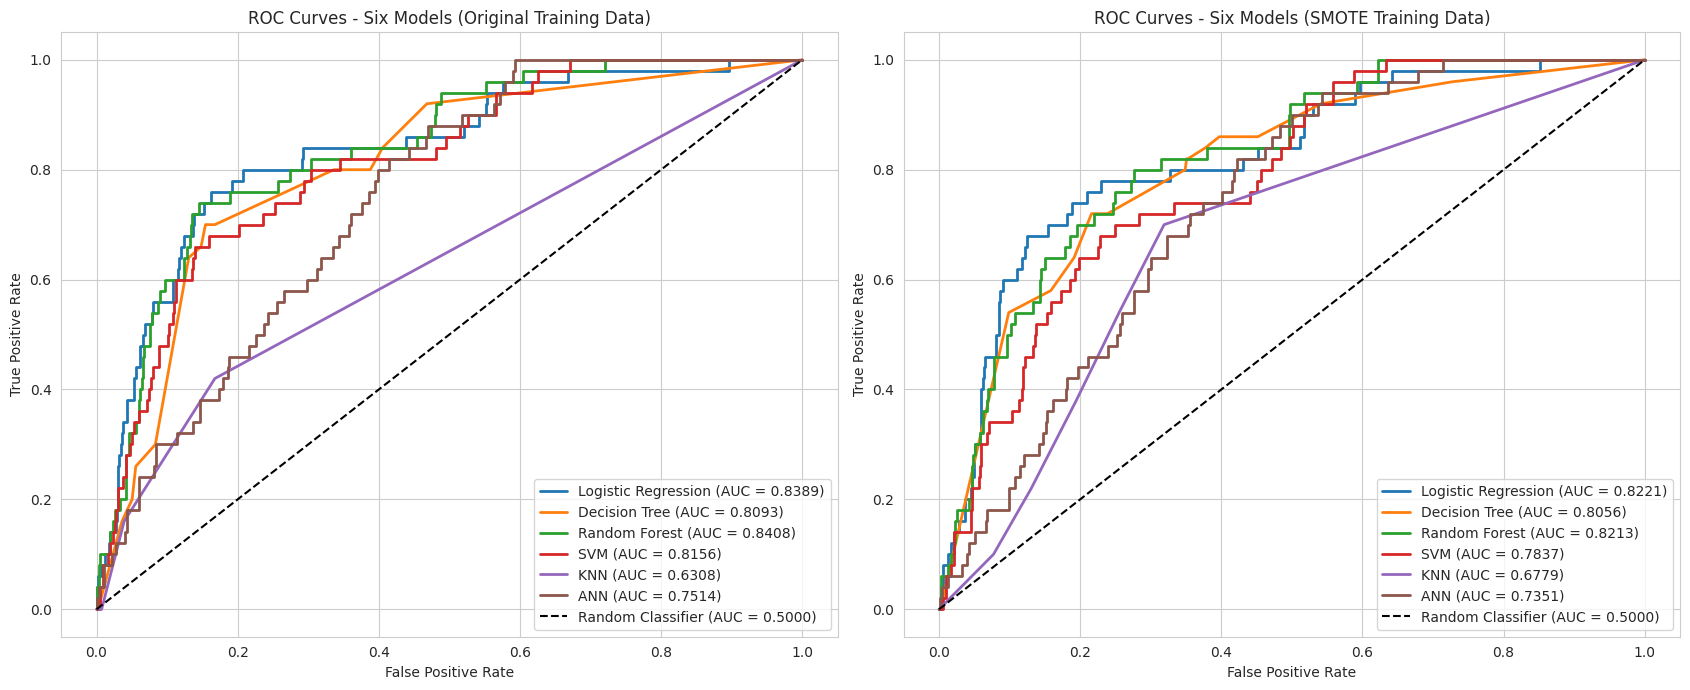

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(17, 7))
plot_roc_curves(store_original, results_original, "Original", axes[0])
plot_roc_curves(store_smote, results_smote, "SMOTE", axes[1])
plt.tight_layout()
plt.show()

## 12. Comparative Performance Analysis

The table below combines the actual results of both experiments (12 rows = 6 models x 2 dataset types). All values are computed from real model predictions on the untouched test set.

In [18]:
frames = []
for name in MODEL_ORDER:
    for dtype, res in [("Original", results_original), ("SMOTE", results_smote)]:
        row = {"Model": name, "Dataset Type": dtype}
        row.update(res.loc[name, METRICS].to_dict())
        frames.append(row)

comparison_df = pd.DataFrame(frames)
print("Final comparative table (original vs SMOTE):")
display(comparison_df.style.format({m: "{:.4f}" for m in METRICS}).hide(axis="index"))

# Change in every metric after SMOTE (SMOTE minus Original)
change_df = (results_smote[METRICS] - results_original[METRICS]).round(4)
print("\nChange after SMOTE (SMOTE - Original); positive = improvement:")
display(change_df.style.format("{:+.4f}"))

Final comparative table (original vs SMOTE):


Model,Dataset Type,Accuracy,Precision,Recall,F1-Score,AUC-ROC
Logistic Regression,Original,0.7515,0.1408,0.8000,0.2395,0.8389
Logistic Regression,SMOTE,0.7593,0.1423,0.7800,0.2407,0.8221
Decision Tree,Original,0.8258,0.1768,0.7000,0.2823,0.8093
Decision Tree,SMOTE,0.7593,0.1343,0.7200,0.2264,0.8056
Random Forest,Original,0.8591,0.2062,0.6600,0.3143,0.8408
Random Forest,SMOTE,0.7534,0.1314,0.7200,0.2222,0.8213
SVM,Original,0.7123,0.1187,0.7600,0.2054,0.8156
SVM,SMOTE,0.7534,0.1259,0.6800,0.2125,0.7837
KNN,Original,0.9442,0.0000,0.0000,0.0000,0.6308
KNN,SMOTE,0.7847,0.0913,0.3800,0.1473,0.6779



Change after SMOTE (SMOTE - Original); positive = improvement:


,Accuracy,Precision,Recall,F1-Score,AUC-ROC
Model,,,,,
Logistic Regression,+0.0078,+0.0015,-0.0200,+0.0012,-0.0168
Decision Tree,-0.0665,-0.0424,+0.0200,-0.0558,-0.0037
Random Forest,-0.1057,-0.0749,+0.0600,-0.0921,-0.0195
SVM,+0.0411,+0.0072,-0.0800,+0.0071,-0.0319
KNN,-0.1595,+0.0913,+0.3800,+0.1473,+0.0472
ANN,-0.0812,-0.0712,+0.1600,+0.0101,-0.0163


## 13. Performance Comparison Graphs

Grouped bar charts compare **Original vs SMOTE** for every classifier and every metric.

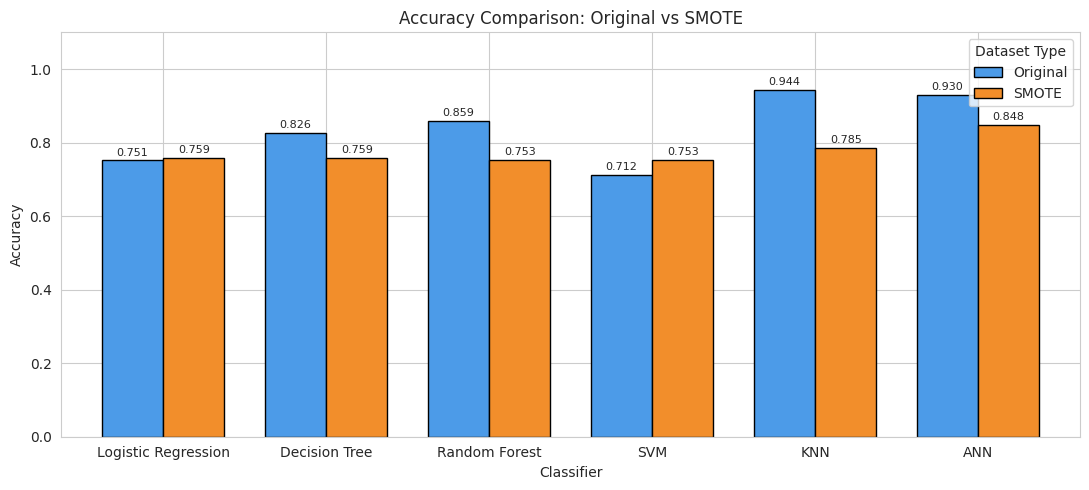

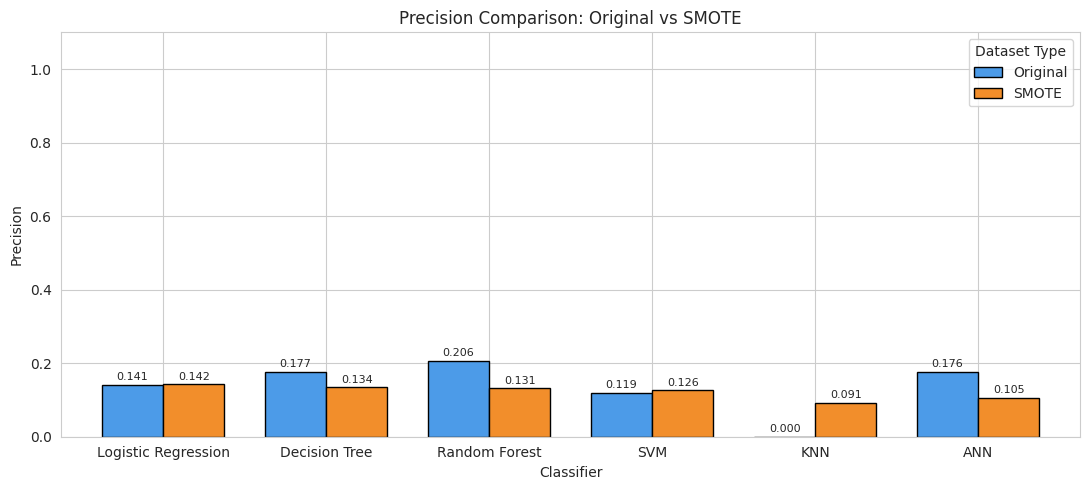

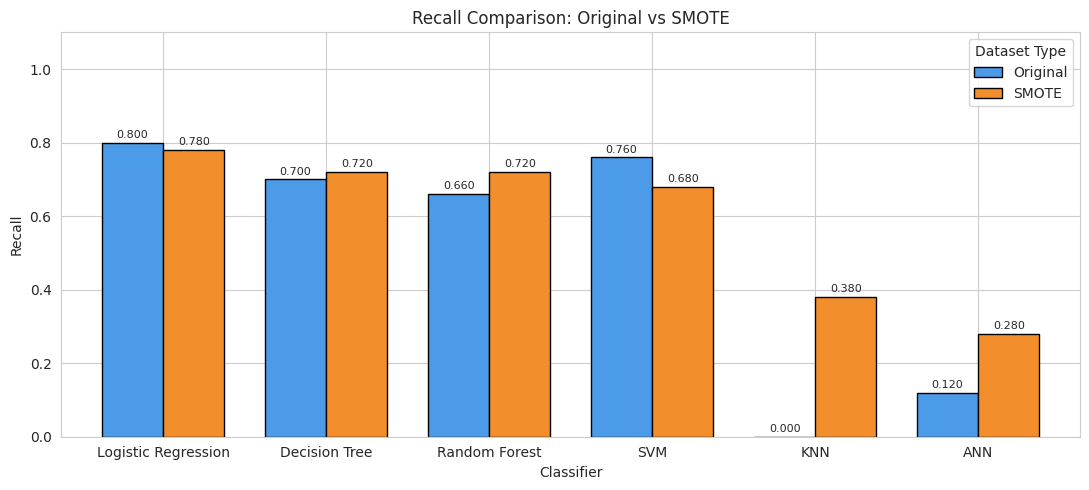

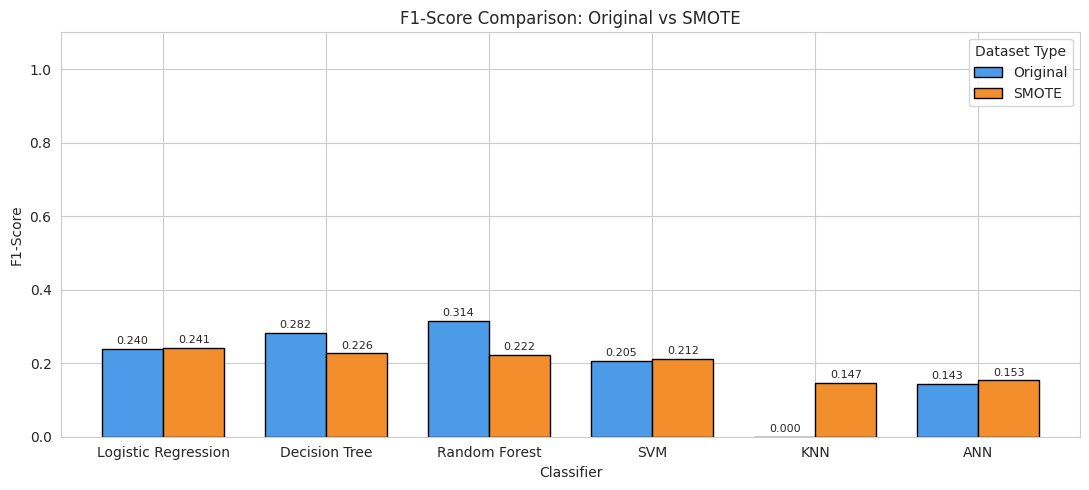

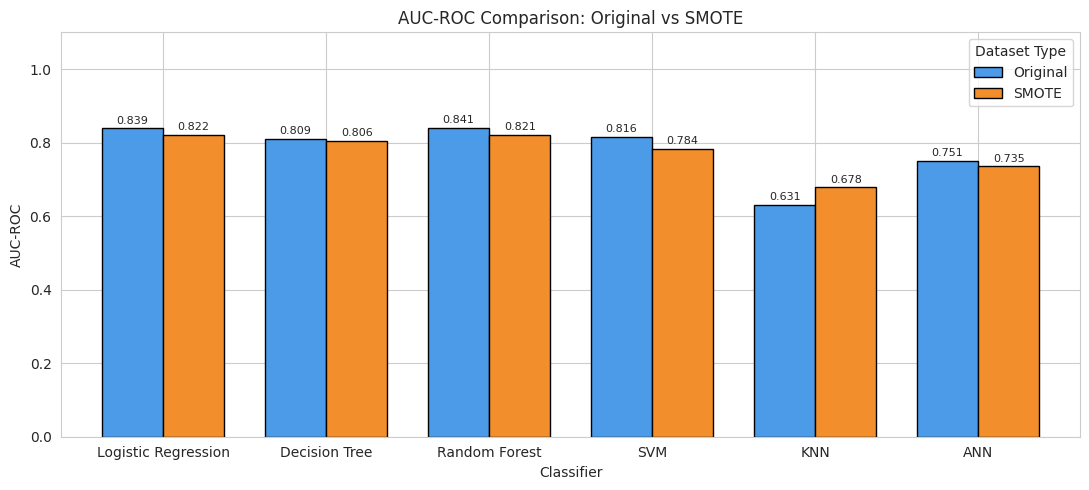

In [19]:
palette = {"Original": "#4c9be8", "SMOTE": "#f28e2b"}

for metric in METRICS:
    pivot = comparison_df.pivot(index="Model", columns="Dataset Type", values=metric).loc[MODEL_ORDER][["Original", "SMOTE"]]
    ax = pivot.plot(kind="bar", figsize=(11, 5), color=[palette["Original"], palette["SMOTE"]],
                    edgecolor="black", width=0.75)
    for container in ax.containers:
        ax.bar_label(container, fmt="%.3f", fontsize=8, padding=2)
    plt.title(f"{metric} Comparison: Original vs SMOTE")
    plt.xlabel("Classifier")
    plt.ylabel(metric)
    plt.ylim(0, 1.1)
    plt.xticks(rotation=0)
    plt.legend(title="Dataset Type", loc="upper right")
    plt.tight_layout()
    plt.show()

## 14. Identify Top Three Models

The top three models are chosen from the **SMOTE experiment** with this ranking criteria:
1. **Primary:** F1-Score (balance of Precision and Recall of the Stroke class)
2. **Secondary:** Recall (ability to find real stroke patients)
3. **Tertiary:** AUC-ROC (overall ranking ability)

The ranking is calculated from the actual results - no model is selected in advance.

In [20]:
ranking = results_smote.sort_values(by=["F1-Score", "Recall", "AUC-ROC"], ascending=False).copy()
ranking.insert(0, "Rank", range(1, len(ranking) + 1))
print("Ranking of all six models on the SMOTE-balanced dataset:")
display(ranking.style.format({m: "{:.4f}" for m in METRICS}))

top3 = ranking.head(3)
top3_names = top3.index.tolist()
print("Top three models:")
display(top3.style.format({m: "{:.4f}" for m in METRICS}))

Ranking of all six models on the SMOTE-balanced dataset:


,Rank,Accuracy,Precision,Recall,F1-Score,AUC-ROC
Model,,,,,,
Logistic Regression,1,0.7593,0.1423,0.7800,0.2407,0.8221
Decision Tree,2,0.7593,0.1343,0.7200,0.2264,0.8056
Random Forest,3,0.7534,0.1314,0.7200,0.2222,0.8213
SVM,4,0.7534,0.1259,0.6800,0.2125,0.7837
ANN,5,0.8483,0.1053,0.2800,0.1530,0.7351
KNN,6,0.7847,0.0913,0.3800,0.1473,0.6779


Top three models:


,Rank,Accuracy,Precision,Recall,F1-Score,AUC-ROC
Model,,,,,,
Logistic Regression,1,0.7593,0.1423,0.7800,0.2407,0.8221
Decision Tree,2,0.7593,0.1343,0.7200,0.2264,0.8056
Random Forest,3,0.7534,0.1314,0.7200,0.2222,0.8213


Why these models performed better (based on the actual results):

Rank 1: Logistic Regression
  - F1-Score 0.2407 (original 0.2395), Recall 0.7800 (original 0.8000), Precision 0.1423 (original 0.1408), AUC-ROC 0.8221.
  - It detected 39 of 50 stroke patients in the test set (missed 11) and raised 235 false alarms among 972 healthy patients.

Rank 2: Decision Tree
  - F1-Score 0.2264 (original 0.2823), Recall 0.7200 (original 0.7000), Precision 0.1343 (original 0.1768), AUC-ROC 0.8056.
  - It detected 36 of 50 stroke patients in the test set (missed 14) and raised 232 false alarms among 972 healthy patients.

Rank 3: Random Forest
  - F1-Score 0.2222 (original 0.3143), Recall 0.7200 (original 0.6600), Precision 0.1314 (original 0.2062), AUC-ROC 0.8213.
  - It detected 36 of 50 stroke patients in the test set (missed 14) and raised 238 false alarms among 972 healthy patients.



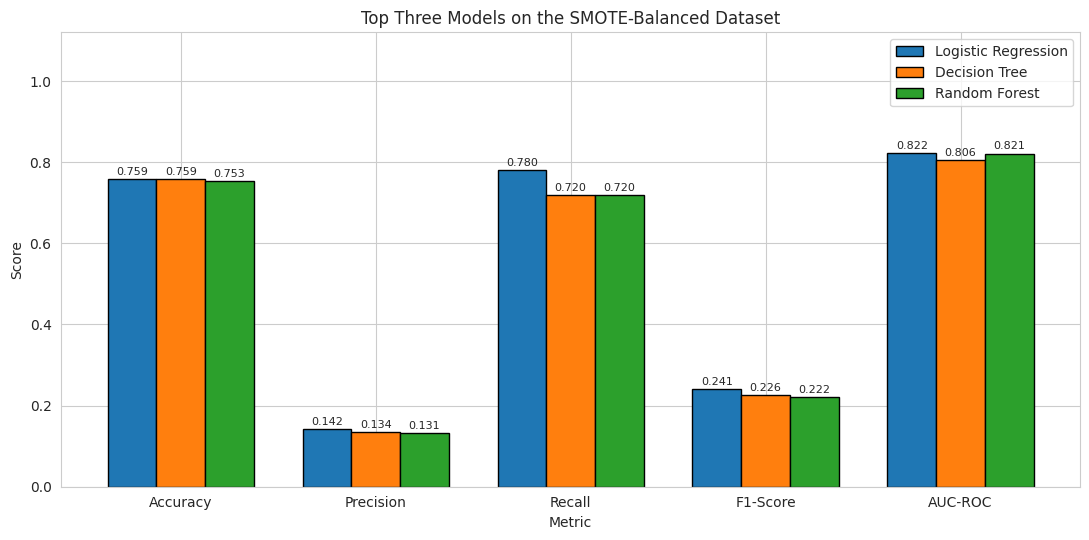

In [21]:
# Explanation generated from the actual metrics
print("Why these models performed better (based on the actual results):\n")
for name in top3_names:
    r = results_smote.loc[name]
    o = results_original.loc[name]
    tn, fp, fn, tp = store_smote[name]["cm"].ravel()
    print(f"Rank {int(top3.loc[name, 'Rank'])}: {name}")
    print(f"  - F1-Score {r['F1-Score']:.4f} (original {o['F1-Score']:.4f}), "
          f"Recall {r['Recall']:.4f} (original {o['Recall']:.4f}), "
          f"Precision {r['Precision']:.4f} (original {o['Precision']:.4f}), "
          f"AUC-ROC {r['AUC-ROC']:.4f}.")
    print(f"  - It detected {tp} of {tp + fn} stroke patients in the test set (missed {fn}) "
          f"and raised {fp} false alarms among {tn + fp} healthy patients.")
    print()

# Top-3 comparison chart
x = np.arange(len(METRICS))
width = 0.25
plt.figure(figsize=(11, 5.5))
for i, name in enumerate(top3_names):
    bars = plt.bar(x + (i - 1) * width, top3.loc[name, METRICS].astype(float), width, label=name, edgecolor="black")
    for b in bars:
        plt.text(b.get_x() + b.get_width() / 2, b.get_height() + 0.01, f"{b.get_height():.3f}",
                 ha="center", fontsize=8)
plt.xticks(x, METRICS)
plt.ylim(0, 1.12)
plt.ylabel("Score")
plt.xlabel("Metric")
plt.title("Top Three Models on the SMOTE-Balanced Dataset")
plt.legend()
plt.tight_layout()
plt.show()

## 15. Final Conclusion

The conclusion below is generated by the code from the **actual results** of this run, so every number and every statement comes from the experiment.

In [22]:
def count_better(metric):
    return int((results_smote[metric] > results_original[metric]).sum())

def count_worse(metric):
    return int((results_smote[metric] < results_original[metric]).sum())

rec_o, rec_s = results_original["Recall"], results_smote["Recall"]
best = ranking.index[0]

print("=" * 90)
print("FINAL CONCLUSION (calculated from the experiment)")
print("=" * 90)

print(f"\n1. Data and setup: {len(df)} records, {int(class_counts[1])} stroke cases ({class_percent[1]:.2f}%). "
      f"SMOTE increased the training set from {len(y_train)} to {len(y_train_smote)} records "
      f"({int(after[1] - before[1])} synthetic stroke samples); the test set ({len(y_test)} records) was not changed.")

print(f"\n2. Stroke detection (Recall): Recall improved for {count_better('Recall')} of 6 models, "
      f"decreased for {count_worse('Recall')} and stayed equal for {6 - count_better('Recall') - count_worse('Recall')}. "
      f"Average Recall changed from {rec_o.mean():.4f} to {rec_s.mean():.4f}.")
for name in MODEL_ORDER:
    print(f"     - {name:<20}: Recall {rec_o[name]:.4f} -> {rec_s[name]:.4f}  ({rec_s[name] - rec_o[name]:+.4f})")

print(f"\n3. Precision: increased for {count_better('Precision')} and decreased for {count_worse('Precision')} models "
      f"(average {results_original['Precision'].mean():.4f} -> {results_smote['Precision'].mean():.4f}).")
print(f"   F1-Score: increased for {count_better('F1-Score')} and decreased for {count_worse('F1-Score')} models "
      f"(average {results_original['F1-Score'].mean():.4f} -> {results_smote['F1-Score'].mean():.4f}).")
print(f"   Accuracy: increased for {count_better('Accuracy')} and decreased for {count_worse('Accuracy')} models "
      f"(average {results_original['Accuracy'].mean():.4f} -> {results_smote['Accuracy'].mean():.4f}).")
print(f"   AUC-ROC : increased for {count_better('AUC-ROC')} and decreased for {count_worse('AUC-ROC')} models "
      f"(average {results_original['AUC-ROC'].mean():.4f} -> {results_smote['AUC-ROC'].mean():.4f}).")

# Honest overall statement about SMOTE (wording depends on the actual counts)
n_rec_up, n_rec_down = count_better("Recall"), count_worse("Recall")
if n_rec_up >= 4:
    verdict = f"SMOTE improved stroke detection (Recall) for most models ({n_rec_up} of 6)."
elif n_rec_down >= 4:
    verdict = f"SMOTE did not improve stroke detection (Recall); it decreased for {n_rec_down} of 6 models."
else:
    verdict = (f"SMOTE had a mixed effect on stroke detection: Recall increased for {n_rec_up}, "
               f"decreased for {n_rec_down} and stayed equal for {6 - n_rec_up - n_rec_down} of 6 models.")
if count_better("F1-Score") < 4:
    verdict += (f" F1-Score improved for only {count_better('F1-Score')} of 6 models, so SMOTE did not improve "
                "every metric - extra stroke cases were found at the cost of more false alarms for several models.")
else:
    verdict += f" F1-Score also improved for {count_better('F1-Score')} of 6 models."
print(f"\n4. Overall effect of SMOTE: {verdict}")

# Did SMOTE help more where the model had no class_weight option (KNN, ANN)?
no_weight = ["KNN", "ANN"]
with_weight = [m for m in MODEL_ORDER if m not in no_weight]
gain_no_weight = (rec_s[no_weight] - rec_o[no_weight]).mean()
gain_with_weight = (rec_s[with_weight] - rec_o[with_weight]).mean()
print(f"   Average Recall change for models WITHOUT class_weight (KNN, ANN): {gain_no_weight:+.4f}; "
      f"for models WITH class_weight='balanced': {gain_with_weight:+.4f}.")

print(f"\n5. Best model on the SMOTE-balanced data: {best} "
      f"(F1-Score {ranking.loc[best, 'F1-Score']:.4f}, Recall {ranking.loc[best, 'Recall']:.4f}, "
      f"AUC-ROC {ranking.loc[best, 'AUC-ROC']:.4f}).")
print(f"   Top three models (F1 -> Recall -> AUC-ROC): {', '.join(top3_names)}.")
best_recall_model = results_smote["Recall"].idxmax()
print(f"   Highest Recall after SMOTE: {best_recall_model} ({results_smote.loc[best_recall_model, 'Recall']:.4f}).")
print("=" * 90)

FINAL CONCLUSION (calculated from the experiment)

1. Data and setup: 5110 records, 249 stroke cases (4.87%). SMOTE increased the training set from 4088 to 7778 records (3690 synthetic stroke samples); the test set (1022 records) was not changed.

2. Stroke detection (Recall): Recall improved for 4 of 6 models, decreased for 2 and stayed equal for 0. Average Recall changed from 0.5067 to 0.5933.
     - Logistic Regression : Recall 0.8000 -> 0.7800  (-0.0200)
     - Decision Tree       : Recall 0.7000 -> 0.7200  (+0.0200)
     - Random Forest       : Recall 0.6600 -> 0.7200  (+0.0600)
     - SVM                 : Recall 0.7600 -> 0.6800  (-0.0800)
     - KNN                 : Recall 0.0000 -> 0.3800  (+0.3800)
     - ANN                 : Recall 0.1200 -> 0.2800  (+0.1600)

3. Precision: increased for 3 and decreased for 3 models (average 0.1365 -> 0.1218).
   F1-Score: increased for 4 and decreased for 2 models (average 0.1974 -> 0.2004).
   Accuracy: increased for 2 and decreased for 

### Limitations of the Experiment
- **Small test set:** the test set has only about 50 stroke patients, so one or two patients change Recall noticeably. A single 80:20 split was used; cross-validation would give more stable results.
- **Synthetic data:** SMOTE interpolates between minority samples. On label-encoded categorical features (e.g. `work_type`, `smoking_status`) the synthetic rows can contain fractional values that are not real categories. SMOTE-NC or one-hot encoding can handle this better.
- **Pre-scaled data:** the supplied processed file was standardized before the split (as in the original lab notebook), so a small amount of information from the test rows is already present in the scaling statistics. The assignment keeps this file unchanged to stay consistent with the original experiment.
- **Fixed settings:** the original hyper-parameters were kept for a fair comparison; no tuning and no probability-threshold tuning was done (the default threshold of 0.5 was used). Models that already use `class_weight="balanced"` receive little extra benefit from SMOTE.
- **Educational use:** the models are for laboratory learning only and are **not** a medical diagnosis tool.